# **CMP6202 AI & Machine Learning: Predicting Population Growth and Decline**
## Regression from A to Z on UN World Population Prospects 2024
Student ID: 23187763

We predict a **number**: a country's **population growth rate** in a year (% per year). A negative prediction means the population is **shrinking**.

| Step | What we do | Code we use |
|---|---|---|
| 1 | **Problem:** class or number? What is the target? | |
| 2 | **Load** the data | `pd.read_csv` |
| 3 | **Clean** it (rows we cannot use, leaking columns, quality checks) | `drop`, `isna`, `duplicated` |
| 4 | **Text → numbers** | not needed: every feature is a number |
| 5 | **Feature engineering** (past information only) | `shift`, `rolling` |
| 6 | **EDA** on the training years | histograms, scatter plots, heatmap |
| 7 | **X and y**, **split by year** and lock the test set | |
| 8 | **Baseline** | `DummyRegressor` |
| 9 | **Test fairly with cross-validation** | `cross_val_score` |
| 10 | **Make it better** | `GridSearchCV`, `RandomizedSearchCV` |
| 11 | **The final test, once**, and **explain** | MAE, RMSE, R², plots |

> **Why we split by year and not at random:** every row is one country in one year, and a country changes very little from one year to the next. A random split would put *Japan 2015* in training and *Japan 2016* in the test set: the model would be tested on near-copies of what it learned (data leakage, Week 3). So we learn from **1955–2003** and test on **2004–2023**, exactly as the model would be used: learn from the past, predict the future.

# **Part 0: Setup**

Put the dataset in a `data/` folder next to this notebook (in Colab: change `DATA_PATH` to your Drive folder).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

DATA_PATH = "data/"
FIG_DIR = "figures/"
import os; os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

# **Step 1: Problem**
- **Question:** how fast is a country's population growing (or shrinking) in a given year?
- **Target:** `PopGrowthRate`, in **% per year**. 1.0 means the population grew by 1% that year; −0.5 means it **shrank** by 0.5%.
- **Type:** a **number** → **regression**. So we use **MAE, RMSE and R²** (Week 5), and `scoring="neg_mean_absolute_error"` (Week 8).

# **Step 2: Load the data**

In [2]:
df = pd.read_csv(DATA_PATH + "WPP2024_Demographic_Indicators_Medium.csv.gz", low_memory=False)
print("Shape:", df.shape)
print(df["LocTypeName"].value_counts())

Shape: (84360, 67)
LocTypeName
Country/Area         36024
Ad Hoc groups         3496
Subregion             3192
SDG region            1368
Income group          1368
Development group     1064
Special other         1064
Geographic region     1064
World                  152
Name: count, dtype: int64


# **Step 3: Clean the data**
## 3.1 Keep only the rows we can use
Every dataset is different: we do only the steps this one needs.
1. **Countries only.** The World, regions and income groups are totals of countries: keeping them would count the same people twice.
2. **Real data only (1950–2023).** From 2024 the file holds UN **projections**, i.e. the output of the UN's own model.
3. **No micro-states.** Places that never reached 100,000 people (e.g. the Holy See) have very noisy rates.

In [3]:
df = df[df["LocTypeName"] == "Country/Area"]
print("1. Countries only      :", df.shape[0], "rows")

df = df[df["Time"] <= 2023]
print("2. Estimates 1950-2023 :", df.shape[0], "rows,", df["Location"].nunique(), "countries")

peak_pop = df.groupby("Location")["TPopulation1July"].transform("max")   # in thousands
df = df[peak_pop >= 100].copy()
print("3. At least 100,000    :", df.shape[0], "rows,", df["Location"].nunique(), "countries")

1. Countries only      : 36024 rows
2. Estimates 1950-2023 : 17538 rows, 237 countries
3. At least 100,000    : 14874 rows, 201 countries


## 3.2 Remove the columns that leak the answer
Growth = births − deaths + net migration. Any column that measures these **in the same year** would let the model **work out the answer with arithmetic** instead of learning. So they are removed from the features. We also leave out ID columns and `Location` (the model must learn demographic patterns, not memorise countries).

In [4]:
TARGET = "PopGrowthRate"

LEAKY = ["TPopulation1Jan", "TPopulation1July", "TPopulationMale1July", "TPopulationFemale1July",
         "PopChange", "DoublingTime", "NatChange", "NatChangeRT", "Births", "Deaths",
         "DeathsMale", "DeathsFemale", "CBR", "CDR", "NetMigrations", "CNMR",
         "InfantDeaths", "Under5Deaths", "Births1519", "LBsurvivingAge1"]

BASE_FEATURES = ["TFR", "NRR", "MAC", "SRB", "MedianAgePop", "PopSexRatio", "PopDensity",
                 "LEx", "LE15", "LE65", "LE80", "IMR", "Q5", "Q0040", "Q0060", "Q1550", "Q1560"]
print(len(BASE_FEATURES), "features kept,", len(LEAKY), "leaking columns removed")

17 features kept, 20 leaking columns removed


## 3.3 Quality checks: missing values, duplicates, impossible values

In [5]:
print("Missing values in features + target:", df[BASE_FEATURES + [TARGET]].isna().sum().sum())
print("Duplicate country-years            :", df.duplicated(["Location", "Time"]).sum())
print("Negative fertility or life expectancy:", ((df["TFR"] < 0) | (df["LEx"] < 0)).sum())
df[BASE_FEATURES + [TARGET]].describe().T.round(2)

Missing values in features + target: 0
Duplicate country-years            : 0
Negative fertility or life expectancy: 0


**What this shows:** no missing values, no duplicates and no impossible values, so there is **nothing to fill or remove**. The features live on very different scales (density goes up to about 22,000 people per km², the mother's mean age stays between 24 and 33), so Linear Regression gets **scaled** features later (fitted on `X_train` only).

# **Step 4: Text → numbers**
Every feature is already a number, so **`LabelEncoder` is not needed here**. `Location` is text, but it is **not** used as a feature.

# **Step 5: Feature engineering (past information only)**
Like `FamilySize` in Week 3, we create new features from existing ones. Each uses **only earlier years**, so it would be known at prediction time:
- `CNMR_prev5`: average net migration rate over the **previous five years** (`shift(1)` = year *t* itself is never used)
- `TFR_change5`, `MedianAge_change5`: change in fertility and in median age over five years
- `LEx_gap`: female minus male life expectancy

In [6]:
df = df.sort_values(["Location", "Time"])
g = df.groupby("Location")
df["CNMR_prev5"] = g["CNMR"].transform(lambda s: s.shift(1).rolling(5).mean())
df["TFR_change5"] = df["TFR"] - g["TFR"].shift(5)
df["MedianAge_change5"] = df["MedianAgePop"] - g["MedianAgePop"].shift(5)
df["LEx_gap"] = df["LExFemale"] - df["LExMale"]

ENG_FEATURES = ["CNMR_prev5", "TFR_change5", "MedianAge_change5", "LEx_gap"]
FEATURES = BASE_FEATURES + ENG_FEATURES

# the 5-year features need 5 earlier years, so the data starts in 1955
data = df[df["Time"] >= 1955].dropna(subset=FEATURES).reset_index(drop=True)
print("Rows:", len(data), "| Countries:", data["Location"].nunique(), "| Years:", data["Time"].min(), "-", data["Time"].max())
data[["Location", "ISO3_code", "Time"] + FEATURES + [TARGET]].to_csv(DATA_PATH + "population_growth_model_data.csv", index=False)

Rows: 13869 | Countries: 201 | Years: 1955 - 2023


# **Step 6: X and y, split by year, lock the test set**
Same four names as always: `X_train, X_test, y_train, y_test`. The test set is **locked** until Step 11, and all EDA below uses the **training years only**.

In [7]:
SPLIT_YEAR = 2003
train = data[data["Time"] <= SPLIT_YEAR].reset_index(drop=True)
test  = data[data["Time"] >  SPLIT_YEAR].reset_index(drop=True)

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print("Training rows (1955-2003):", len(X_train), f"({len(X_train)/len(data):.0%})")
print("Test rows     (2004-2023):", len(X_test),  f"({len(X_test)/len(data):.0%})")
print("Average growth: train", round(y_train.mean(), 2), "% | test", round(y_test.mean(), 2), "%")

Training rows (1955-2003): 9849 (71%)
Test rows     (2004-2023): 4020 (29%)
Average growth: train 2.0 % | test 1.34 %


# **Step 7: EDA on the training years**
## 7.1 The target, one variable at a time

Mean: 2.0 | Median: 2.05 | Std: 2.1
Shrinking (growth < 0): 515 of 9849 (5.2%)
IQR outliers: 309
            Location  Time  PopGrowthRate
              Kuwait  1990        -71.064
              Rwanda  1994        -41.785
China, Hong Kong SAR  1964         37.887
    China, Macao SAR  1964         37.095
              Kuwait  1991         36.090
China, Hong Kong SAR  1967        -33.038


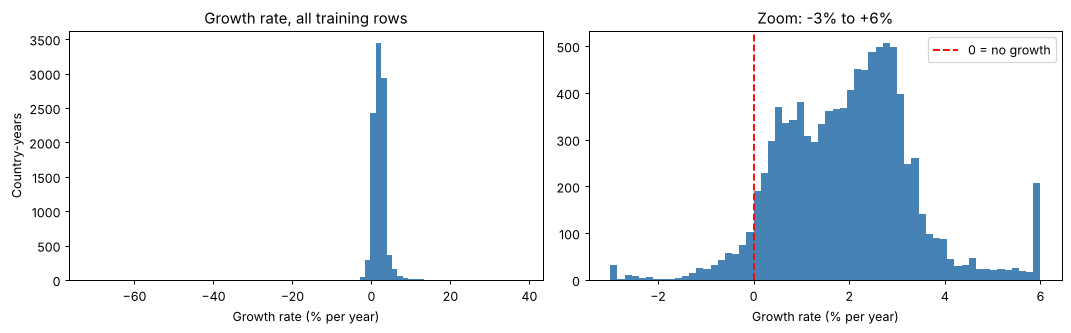

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(y_train, bins=80, color="steelblue")
axes[0].set_title("Growth rate, all training rows"); axes[0].set_xlabel("Growth rate (% per year)"); axes[0].set_ylabel("Country-years")
axes[1].hist(y_train.clip(-3, 6), bins=60, color="steelblue")
axes[1].axvline(0, color="red", ls="--", label="0 = no growth")
axes[1].set_title("Zoom: -3% to +6%"); axes[1].set_xlabel("Growth rate (% per year)"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR + "fig_target_hist.png", dpi=150); plt.show()

print("Mean:", round(y_train.mean(), 2), "| Median:", round(y_train.median(), 2), "| Std:", round(y_train.std(), 2))
print("Shrinking (growth < 0):", (y_train < 0).sum(), "of", len(y_train), f"({(y_train < 0).mean():.1%})")
Q1, Q3 = y_train.quantile([0.25, 0.75]); IQR = Q3 - Q1
print("IQR outliers:", ((y_train < Q1 - 1.5*IQR) | (y_train > Q3 + 1.5*IQR)).sum())
print(train.loc[y_train.abs().nlargest(6).index, ["Location", "Time", TARGET]].to_string(index=False))

**What this shows:** most country-years grow by between about 1% and 3% a year (median **2.05%**), and only **5.2%** of training rows are shrinking. The tails are very long: Kuwait fell by **71%** in 1990 (the Iraqi invasion) and Rwanda by **42%** in 1994 (the genocide). The IQR rule flags **309** rows. These are real events, not typing errors, so we **keep** them (Week 3: an outlier can be signal). A few 1960s values for Hong Kong and Macao look unusual, but nothing proves they are wrong, so they stay too. Because a few huge values exist, **RMSE will be much bigger than MAE**, so MAE is our main score.

## 7.2 Features against the target (two variables together)

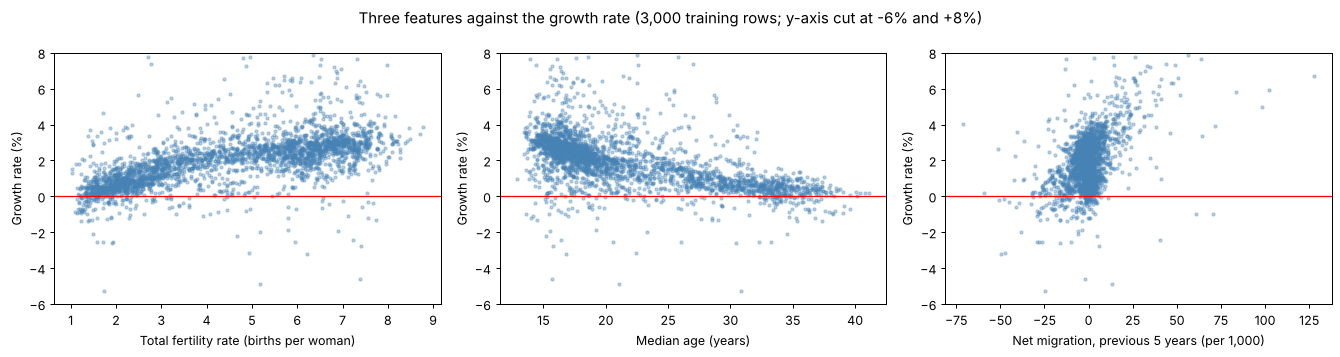

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
s = train.sample(3000, random_state=42)
for ax, col, lab in zip(axes, ["TFR", "MedianAgePop", "CNMR_prev5"],
                        ["Total fertility rate (births per woman)", "Median age (years)",
                         "Net migration, previous 5 years (per 1,000)"]):
    ax.scatter(s[col], s[TARGET], s=6, alpha=0.35, color="steelblue")
    ax.axhline(0, color="red", lw=1)
    ax.set_xlabel(lab); ax.set_ylabel("Growth rate (%)"); ax.set_ylim(-6, 8)
fig.suptitle("Three features against the growth rate (3,000 training rows; y-axis cut at -6% and +8%)")
plt.tight_layout(); plt.savefig(FIG_DIR + "fig_scatter.png", dpi=150); plt.show()

**What this shows:** each dot is one country-year. Lower fertility and older populations go with lower growth, and recent **emigration** (negative migration) goes with shrinking. The dots form **wide clouds, not lines**: no single feature predicts growth on its own, so we need several features together.

## 7.3 Correlation (all variables together)

NRR                  0.49
TFR                  0.44
MedianAgePop        -0.40
CNMR_prev5           0.34
PopSexRatio          0.33
MAC                  0.29
LEx_gap             -0.26
IMR                  0.24
LE65                -0.24
LEx                 -0.23
Q0060                0.23
LE80                -0.22
Q5                   0.22
MedianAge_change5   -0.22
Q0040                0.21
LE15                -0.20
SRB                 -0.18
Q1560                0.18
Q1550                0.16
TFR_change5          0.04
PopDensity          -0.03
Name: PopGrowthRate, dtype: float64


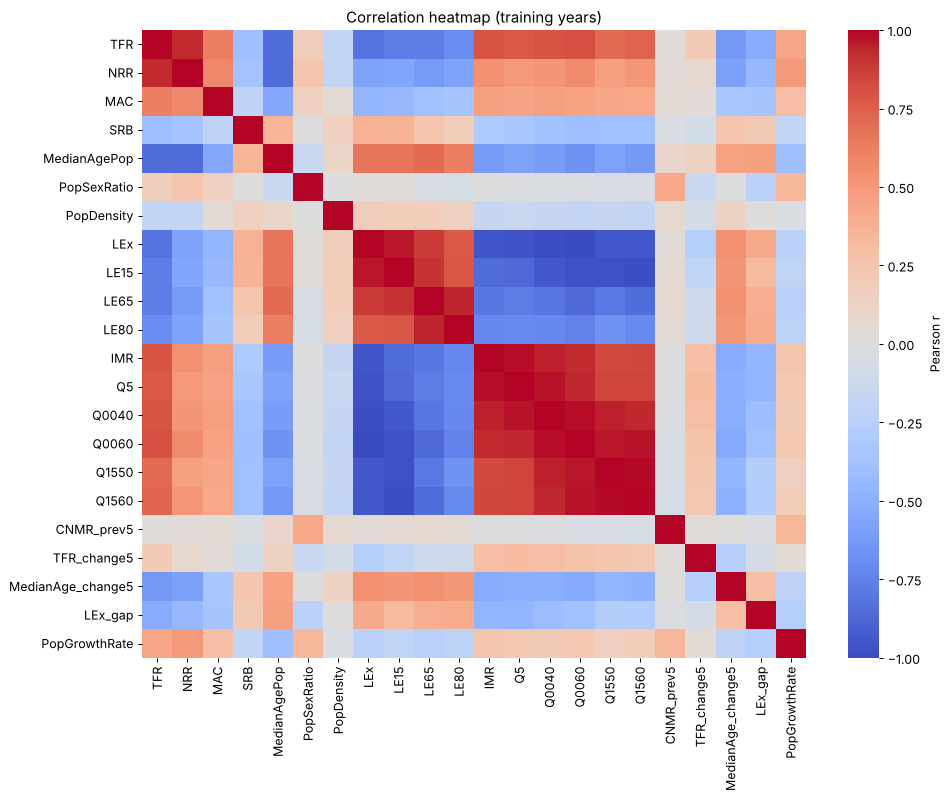

In [10]:
corr = train[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("Correlation heatmap (training years)")
plt.tight_layout(); plt.savefig(FIG_DIR + "fig_corr.png", dpi=150); plt.show()
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2))

**What this shows:** look at the target row first. The strongest links with growth are **NRR (+0.49)**, **TFR (+0.44)**, **median age (−0.40)** and our new feature **CNMR_prev5 (+0.34)**. Then look between the inputs: life expectancy and the mortality columns are almost the same information (bright squares). This **redundancy** will make Linear Regression's weights unstable (hard to read one by one), but it does not hurt trees. A weak correlation does not make a feature useless: trees can use curved patterns.

# **Step 8: Baseline**
The baseline for a number is: **always guess the average growth rate**. Any real model must beat it.

## Cross-validation that respects time
The labs use `KFold(shuffle=True)`. Here a shuffled fold would mix neighbouring years of the same country (leakage again), so we build **5 folds on whole years**: each round learns from the **earlier** years and is tested on the **next** block of years. `cross_val_score` accepts this list through `cv=`, exactly like `cv=kf`.

In [11]:
def year_folds(frame, n_splits=5):
    years = np.sort(frame["Time"].unique())
    blocks = np.array_split(years, n_splits + 1)
    folds = []
    for k in range(1, n_splits + 1):
        learn = np.where(frame["Time"].isin(np.concatenate(blocks[:k])))[0]
        check = np.where(frame["Time"].isin(blocks[k]))[0]
        folds.append((learn, check))
    return folds

cv_years = year_folds(train)
for i, (a, b) in enumerate(cv_years, 1):
    print(f"Round {i}: learn {train.Time[a].min()}-{train.Time[a].max()} | test {train.Time[b].min()}-{train.Time[b].max()}")

baseline = DummyRegressor(strategy="mean")
base_scores = cross_val_score(baseline, X_train, y_train, cv=cv_years, scoring="neg_mean_absolute_error")
print("\nBaseline MAE:", round(-base_scores.mean(), 3), "percentage points")

Round 1: learn 1955-1963 | test 1964-1971
Round 2: learn 1955-1971 | test 1972-1979
Round 3: learn 1955-1979 | test 1980-1987
Round 4: learn 1955-1987 | test 1988-1995
Round 5: learn 1955-1995 | test 1996-2003

Baseline MAE: 1.232 percentage points


# **Step 9: Test fairly with cross-validation**
## 9.1 Compare models fairly
Every model gets the **same** 5 rounds. Linear Regression sits in a `Pipeline` with `StandardScaler`, so the scaler is **fitted on the learning part of each round only** (Week 3 rule: fit on train, transform test).

In [12]:
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}
cv_mae = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv_years, scoring="neg_mean_absolute_error")
    cv_mae[name] = -scores
    print(f"{name:18s} MAE per round: {(-scores).round(3)}  average {(-scores).mean():.3f}  (moves {scores.std():.3f})")

Baseline (mean)    MAE per round: [1.124 1.197 1.161 1.394 1.282]  average 1.232  (moves 0.096)
Linear Regression  MAE per round: [0.505 0.498 0.463 0.711 0.581]  average 0.552  (moves 0.089)
Decision Tree      MAE per round: [0.783 0.825 0.704 1.145 0.865]  average 0.865  (moves 0.150)
Random Forest      MAE per round: [0.538 0.556 0.531 0.709 0.611]  average 0.589  (moves 0.066)


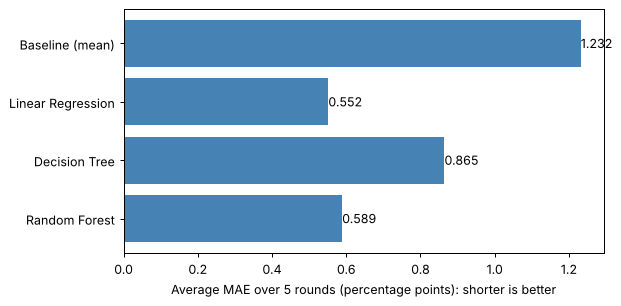

In [13]:
names = list(cv_mae.keys())
errors = [cv_mae[n].mean() for n in names]
plt.figure(figsize=(7, 3.5))
bars = plt.barh(names, errors, color="steelblue")
plt.bar_label(bars, fmt="%.3f")
plt.xlabel("Average MAE over 5 rounds (percentage points): shorter is better")
plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig(FIG_DIR + "fig_cv_compare.png", dpi=150); plt.show()

**What this shows:** each bar is a model's **average miss** over the 5 rounds. **Shorter is better.** Guessing the average misses by **1.232** percentage points. **Linear Regression (0.552)** is already better than the default **Random Forest (0.589)**, and the default **Decision Tree (0.865)** is clearly worse: with no limit it memorises the training years. Trees have settings to tune, so we tune them next.

## 9.2 Why not shuffled KFold? Measure the leak

In [14]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for name in ["Linear Regression", "Decision Tree", "Random Forest"]:
    shuffled = cross_val_score(models[name], X_train, y_train, cv=kf, scoring="neg_mean_absolute_error")
    print(f"{name:18s} shuffled KFold MAE {(-shuffled).mean():.3f}  vs  by-year MAE {cv_mae[name].mean():.3f}")

Linear Regression  shuffled KFold MAE 0.549  vs  by-year MAE 0.552
Decision Tree      shuffled KFold MAE 0.467  vs  by-year MAE 0.865
Random Forest      shuffled KFold MAE 0.369  vs  by-year MAE 0.589


**What this shows:** shuffled `KFold` makes the tree look like **0.467** instead of **0.865**, and the forest **0.369** instead of **0.589**. Linear Regression barely changes (0.549 vs 0.552) because a straight line cannot memorise single countries. The flexible models were "recognising" neighbouring years of the same country. Using shuffled folds would have **fooled us** into picking the wrong model, so we keep the year-based folds.

# **Step 10: Make it better by searching for the best settings**
Hyperparameters are settings **we choose** before training. Both search tools use cross-validation on `X_train` only.

## 10.1 `GridSearchCV`: one setting, and overfitting
With `return_train_score=True` we keep the training error too, so we can **see** overfitting.

Best setting: {'max_depth': 10} | Best MAE: 0.768
 max_depth  train MAE  CV MAE
         2      0.701   0.846
         3      0.642   0.879
         4      0.577   0.836
         5      0.532   0.867
         6      0.459   0.828
         8      0.362   0.789
        10      0.281   0.768
        15      0.125   0.814
        20      0.035   0.831


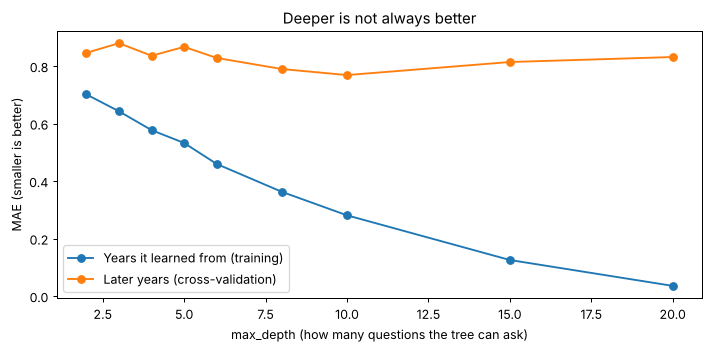

In [15]:
param_grid = {"max_depth": [2, 3, 4, 5, 6, 8, 10, 15, 20]}
grid_tree = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid, cv=cv_years,
                         scoring="neg_mean_absolute_error", return_train_score=True)
grid_tree.fit(X_train, y_train)
print("Best setting:", grid_tree.best_params_, "| Best MAE:", round(-grid_tree.best_score_, 3))

depths = param_grid["max_depth"]
plt.figure(figsize=(8, 4))
plt.plot(depths, -grid_tree.cv_results_["mean_train_score"], marker="o", label="Years it learned from (training)")
plt.plot(depths, -grid_tree.cv_results_["mean_test_score"], marker="o", label="Later years (cross-validation)")
plt.xlabel("max_depth (how many questions the tree can ask)"); plt.ylabel("MAE (smaller is better)")
plt.title("Deeper is not always better"); plt.legend(); plt.tight_layout()
plt.savefig(FIG_DIR + "fig_depth_overfit.png", dpi=150); plt.show()
print(pd.DataFrame({"max_depth": depths, "train MAE": -grid_tree.cv_results_["mean_train_score"],
                    "CV MAE": -grid_tree.cv_results_["mean_test_score"]}).round(3).to_string(index=False))

**What this shows:** for MAE, **lower is better**. The **blue line** (years the tree learned from) falls to **0.035** at depth 20: a deep tree **memorises** its training rows. The **orange line** (later years) does not keep falling. The best depth is **10**, with an average MAE of **0.768**. The gap between the lines is **overfitting**. The orange line is bumpy because each round contains different crisis years.

## 10.2 `GridSearchCV` for a Random Forest: three settings

In [16]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [6, 10, None],
    "min_samples_leaf": [1, 10],
}
grid_rf = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), param_grid,
                       cv=cv_years, scoring="neg_mean_absolute_error", return_train_score=True)
grid_rf.fit(X_train, y_train)
print("Best settings:", grid_rf.best_params_, "| Best MAE:", round(-grid_rf.best_score_, 3))

results = pd.DataFrame(grid_rf.cv_results_)
results["CV MAE"] = -results["mean_test_score"]; results["train MAE"] = -results["mean_train_score"]
print(results[["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "train MAE", "CV MAE", "rank_test_score"]]
      .sort_values("rank_test_score").head(5).round(3).to_string(index=False))

Best settings: {'max_depth': None, 'min_samples_leaf': 10, 'n_estimators': 200} | Best MAE: 0.553
 param_n_estimators param_max_depth  param_min_samples_leaf  train MAE  CV MAE  rank_test_score
                200            None                      10      0.260   0.553                1
                100            None                      10      0.260   0.556                2
                200              10                      10      0.297   0.562                3
                100              10                      10      0.297   0.564                4
                200            None                       1      0.102   0.583                5


**What this shows:** `GridSearchCV` tried **12 combinations** (60 models). The winner is **200 trees, no depth limit, at least 10 rows per leaf**, with an average MAE of **0.553**. Forcing each leaf to hold 10 rows (instead of 1) is what helps: the training MAE rises from 0.102 to 0.260, but the cross-validation MAE falls from 0.583 to 0.553. The forest memorises less and predicts later years better.

## 10.3 `RandomizedSearchCV`: try a random sample of a bigger space

In [17]:
param_random = {
    "n_estimators": [100, 200, 300],
    "max_depth": [6, 8, 10, 15, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "max_features": [1.0, 0.5, "sqrt"],
}
random_rf = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), param_random,
                               n_iter=12, cv=cv_years, scoring="neg_mean_absolute_error", random_state=42)
random_rf.fit(X_train, y_train)
print("Combinations in the space:", 3 * 5 * 4 * 3, "| tried:", 12)
print("Best settings:", random_rf.best_params_, "| Best MAE:", round(-random_rf.best_score_, 3))

Combinations in the space: 180 | tried: 12
Best settings: {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 1.0, 'max_depth': 15} | Best MAE: 0.548


**What this shows:** the space has **180** combinations (900 models with 5 rounds). `RandomizedSearchCV` tried only **12** (60 models) and found a slightly better setting (**MAE 0.548**: 200 trees, depth 15, at least 20 rows per leaf, all features at each split). We keep whichever search scored best on cross-validation; the test set was not used to choose.

## 10.4 Linear Regression has nothing to tune, so we keep it as the simple, explainable model

# **Step 11: The final test, once**
Now, and only now, we open the **test set** (2004–2023). Every model learned only from 1955–2003. We report the three Week 5 scores: **MAE** (typical miss), **RMSE** (big misses count extra) and **R²** (share of the baseline's error removed).

In [18]:
best_rf = grid_rf if -grid_rf.best_score_ <= -random_rf.best_score_ else random_rf
final_models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree (default)": DecisionTreeRegressor(random_state=42),
    "Decision Tree (tuned)": grid_tree.best_estimator_,
    "Random Forest (default)": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Random Forest (tuned)": best_rf.best_estimator_,
}
rows, preds, seen = [], {}, []
for name, model in final_models.items():
    if "tuned" not in name:
        model.fit(X_train, y_train)            # tuned models are already trained on X_train
    p_train = model.predict(X_train); y_pred = model.predict(X_test); preds[name] = y_pred
    seen.append([name, mean_absolute_error(y_train, p_train), mean_squared_error(y_train, p_train) ** 0.5, r2_score(y_train, p_train)])
    rows.append([name, mean_absolute_error(y_test, y_pred), mean_squared_error(y_test, y_pred) ** 0.5, r2_score(y_test, y_pred)])
seen_table = pd.DataFrame(seen, columns=["Model", "MAE", "RMSE", "R2"]).set_index("Model").round(3)
test_table = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE", "R2"]).set_index("Model").round(3)
print("SEEN data (training years 1955-2003):"); print(seen_table)
print("\nUNSEEN data (test years 2004-2023):"); print(test_table)

SEEN data (training years 1955-2003):
                           MAE   RMSE     R2
Model                                       
Baseline (mean)          1.179  2.104  0.000
Linear Regression        0.541  1.651  0.384
Decision Tree (default)  0.000  0.000  1.000
Decision Tree (tuned)    0.429  0.797  0.857
Random Forest (default)  0.132  0.598  0.919
Random Forest (tuned)    0.371  1.495  0.495

UNSEEN data (test years 2004-2023):
                           MAE   RMSE     R2
Model                                       
Baseline (mean)          1.309  1.755 -0.166
Linear Regression        0.524  1.055  0.579
Decision Tree (default)  0.678  1.335  0.326
Decision Tree (tuned)    0.605  1.237  0.421
Random Forest (default)  0.510  1.085  0.554
Random Forest (tuned)    0.493  1.079  0.559


**What this shows:**
- **Seen vs unseen:** the default tree has an MAE of **0.000** on the years it learned from but **0.678** on new years: it memorised them (overfitting). Tuning brings it to **0.605**.
- The **tuned Random Forest** has the lowest MAE (**0.493**, about half a percentage point of growth per year). **Linear Regression** is very close (**0.524**) and has the best **RMSE (1.055)** and **R² (0.579)**, so it makes fewer very large misses.
- The baseline's R² is **below 0 (−0.166)**: the training years' average growth (2.0%) is higher than growth in 2004–2023 (1.34%), so even "guess the average" is out of date.
- Tuning helped, honestly a little: forest **0.510 → 0.493**, tree **0.678 → 0.605**.

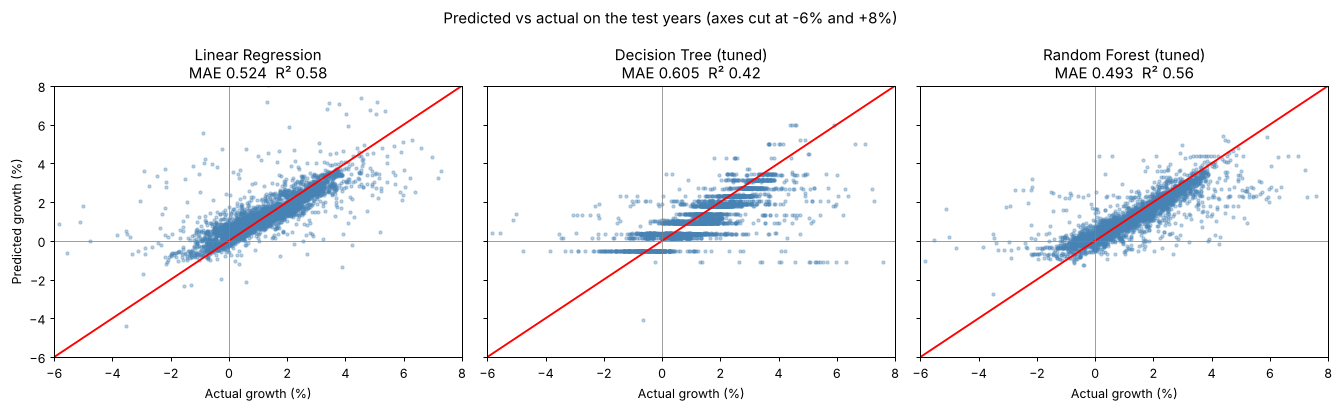

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, name in zip(axes, ["Linear Regression", "Decision Tree (tuned)", "Random Forest (tuned)"]):
    ax.scatter(y_test, preds[name], s=6, alpha=0.35, color="steelblue")
    ax.plot([-6, 8], [-6, 8], color="red")
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
    ax.set_xlim(-6, 8); ax.set_ylim(-6, 8)
    ax.set_title(f"{name}\nMAE {test_table.loc[name, 'MAE']:.3f}  R² {test_table.loc[name, 'R2']:.2f}")
    ax.set_xlabel("Actual growth (%)")
axes[0].set_ylabel("Predicted growth (%)")
fig.suptitle("Predicted vs actual on the test years (axes cut at -6% and +8%)")
plt.tight_layout(); plt.savefig(FIG_DIR + "fig_pred_vs_actual.png", dpi=150); plt.show()

**What this shows:** each dot is one test country-year. Dots **on the red line** are perfect predictions. Most dots sit close to the line between 0% and 4%. Dots far to the right (very high actual growth, such as Gulf states during building booms) are **predicted too low** by every model. The tree's dots sit in **flat rows**: every country-year in the same leaf gets the same prediction.

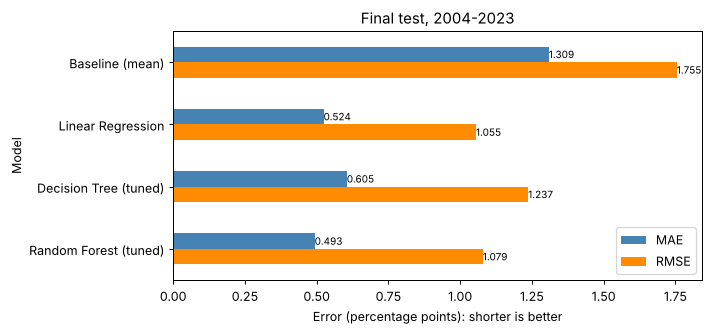

In [20]:
comp = test_table.drop(index=["Decision Tree (default)", "Random Forest (default)"])
ax = comp[["MAE", "RMSE"]].plot(kind="barh", figsize=(8, 3.8), color=["steelblue", "darkorange"])
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("Error (percentage points): shorter is better")
ax.set_title("Final test, 2004-2023"); plt.tight_layout()
plt.savefig(FIG_DIR + "fig_final_compare.png", dpi=150); plt.show()

# **Step 12: Explain the result**
## 12.1 Where are the big misses? (residuals)

Best model: Random Forest (tuned)
Biggest misses:
            Location  Time  PopGrowthRate  pred
               Qatar  2006          22.14  4.28
               Qatar  2007          21.35  3.81
                Oman  2011          18.00  3.10
             Ukraine  2022         -14.76 -0.56
             Curaçao  2018          14.12  0.52
             Lebanon  2013          14.19  1.43
United Arab Emirates  2007          13.84  2.28
               Qatar  2008          12.60  2.76


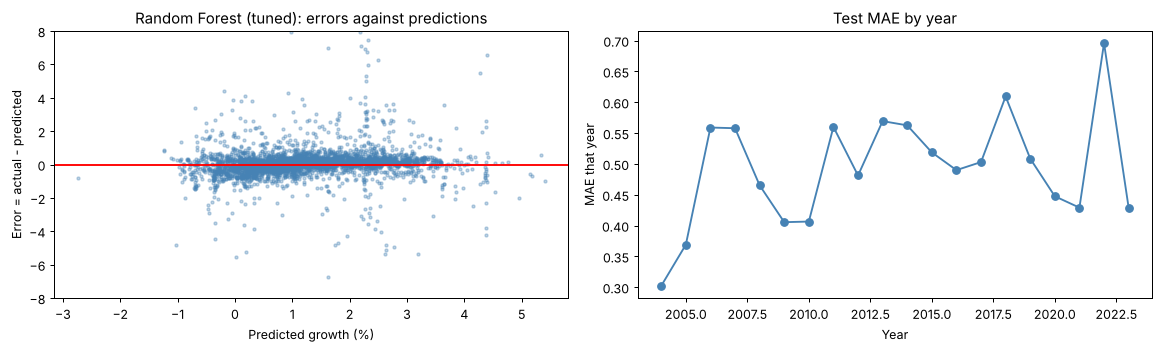

In [21]:
best_name = test_table.drop(index="Baseline (mean)")["MAE"].idxmin()
res = test.assign(pred=preds[best_name], error=y_test - preds[best_name])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(res["pred"], res["error"], s=6, alpha=0.35, color="steelblue"); axes[0].axhline(0, color="red")
axes[0].set_xlabel("Predicted growth (%)"); axes[0].set_ylabel("Error = actual - predicted"); axes[0].set_ylim(-8, 8)
axes[0].set_title(f"{best_name}: errors against predictions")
yearly = res.groupby("Time")["error"].apply(lambda e: e.abs().mean())
axes[1].plot(yearly.index, yearly.values, marker="o", color="steelblue")
axes[1].set_xlabel("Year"); axes[1].set_ylabel("MAE that year"); axes[1].set_title("Test MAE by year")
plt.tight_layout(); plt.savefig(FIG_DIR + "fig_residuals.png", dpi=150); plt.show()
print("Best model:", best_name)
print("Biggest misses:"); print(res.loc[res["error"].abs().nlargest(8).index, ["Location", "Time", TARGET, "pred"]].round(2).to_string(index=False))

**What this shows:** the errors are centred on 0 for most predictions, but a few are very large. The biggest misses are **sudden migration shocks**: Qatar 2006–2008, Oman 2011 and the UAE 2007 (labour migration booms), Lebanon 2013 (Syrian refugees) and **Ukraine 2022** (war: −14.8% actual vs −0.6% predicted). None of our features can see a shock in the same year, which is a limitation of the data, not a bug in the model.

## 12.2 Does the model spot shrinking populations? (sign of the prediction)

In [22]:
for name in ["Linear Regression", "Random Forest (tuned)"]:
    actual_down = y_test < 0; pred_down = preds[name] < 0
    caught = (actual_down & pred_down).sum()
    print(f"{name:22s}: {actual_down.sum()} shrinking country-years, {caught} predicted negative ({caught/actual_down.sum():.0%}); "
          f"{(~actual_down & pred_down).sum()} false alarms; sign correct {np.mean(actual_down == pred_down):.1%}")

Linear Regression     : 625 shrinking country-years, 296 predicted negative (47%); 50 false alarms; sign correct 90.6%
Random Forest (tuned) : 625 shrinking country-years, 315 predicted negative (50%); 100 false alarms; sign correct 89.8%


**What this shows:** even though the model predicts a number, its **sign** tells a planner whether a population is shrinking. The forest predicts a negative number for **315 of the 625** shrinking country-years (about half) and gets the sign right **89.8%** of the time. Linear Regression catches slightly fewer (296) but raises half as many false alarms (50 vs 100).

## 12.3 Which features matter?

NRR             0.797
CNMR_prev5      0.331
MedianAgePop    0.207
Q1550           0.040
PopSexRatio     0.014
TFR             0.011
LE65            0.006
LEx_gap         0.005
PopDensity      0.004
Q1560           0.002
dtype: float64

LEx     -14.747
LE15     12.121
Q0060    -6.608
Q1560     6.397
Q5       -3.063
Q1550     2.329
Q0040    -2.115
NRR       1.786
TFR      -1.296
LE65     -1.028
dtype: float64


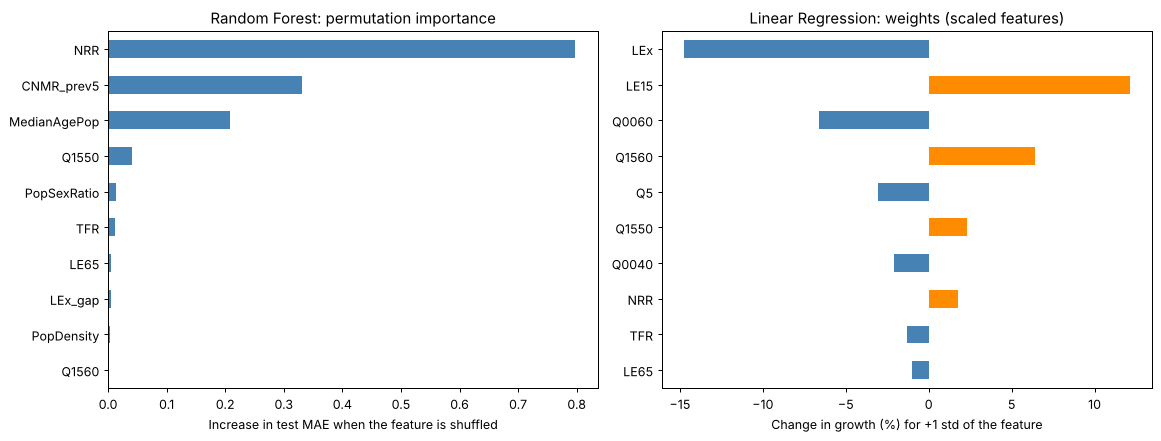

In [23]:
rf = final_models["Random Forest (tuned)"]
perm = permutation_importance(rf, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
coef = pd.Series(final_models["Linear Regression"].named_steps["model"].coef_, index=FEATURES).sort_values(key=abs, ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
imp.head(10)[::-1].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Random Forest: permutation importance"); axes[0].set_xlabel("Increase in test MAE when the feature is shuffled")
coef.head(10)[::-1].plot.barh(ax=axes[1], color=["darkorange" if v > 0 else "steelblue" for v in coef.head(10)[::-1]])
axes[1].set_title("Linear Regression: weights (scaled features)"); axes[1].set_xlabel("Change in growth (%) for +1 std of the feature")
plt.tight_layout(); plt.savefig(FIG_DIR + "fig_importance.png", dpi=150); plt.show()
print(imp.round(3).head(10)); print(); print(coef.round(3).head(10))

**What this shows:** shuffling **NRR** (daughters per woman) makes the forest's test MAE worse by **0.80**, by far the most important feature, followed by our engineered **CNMR_prev5 (0.33)** and **median age (0.21)**: reproduction, recent migration and ageing drive growth. Linear Regression's weights are huge and of opposite signs for near-duplicate features (**LEx −14.7, LE15 +12.1**): this is the redundancy seen in the heatmap, so its single weights should not be read as causes.

# **Appendix**

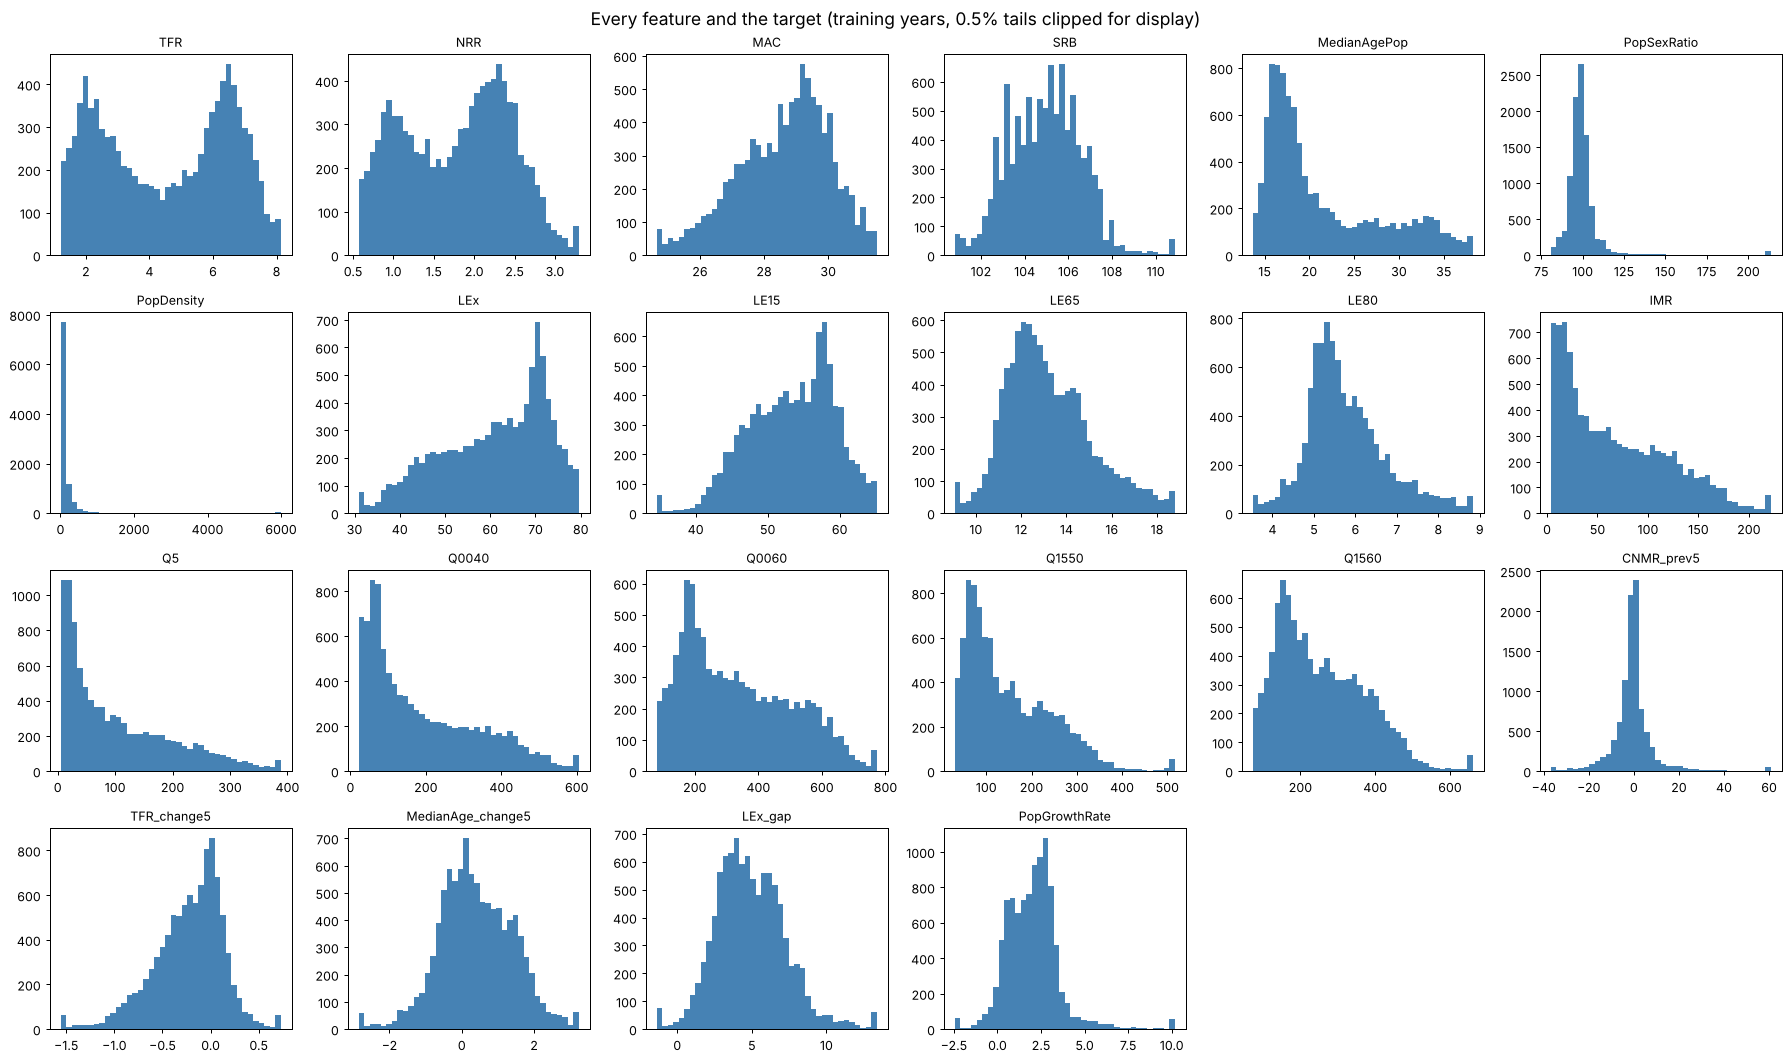

In [24]:
fig, axes = plt.subplots(4, 6, figsize=(20, 12)); axes = axes.ravel()
for ax, col in zip(axes, FEATURES + [TARGET]):
    ax.hist(train[col].clip(train[col].quantile(0.005), train[col].quantile(0.995)), bins=40, color="steelblue")
    ax.set_title(col, fontsize=10)
for ax in axes[len(FEATURES) + 1:]: ax.axis("off")
fig.suptitle("Every feature and the target (training years, 0.5% tails clipped for display)", fontsize=14)
plt.tight_layout(); plt.savefig(FIG_DIR + "figA1_all_hist.png", dpi=110); plt.show()

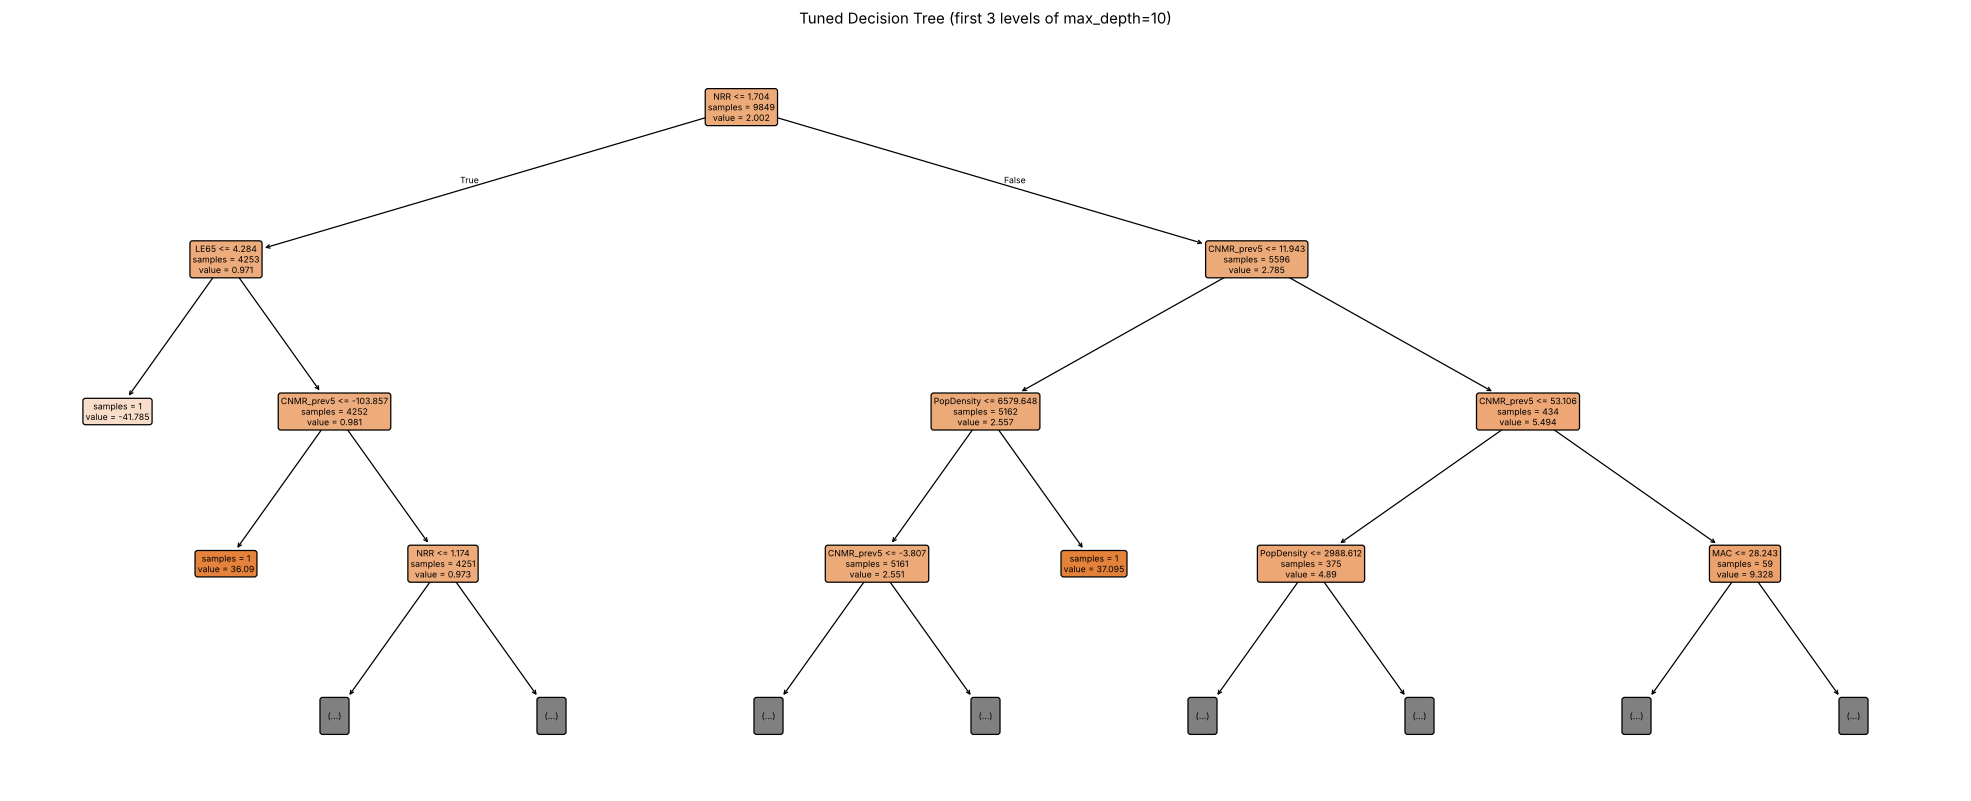

In [25]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(grid_tree.best_estimator_, feature_names=FEATURES, filled=True, rounded=True,
          fontsize=7, ax=ax, impurity=False, max_depth=3)
ax.set_title(f"Tuned Decision Tree (first 3 levels of max_depth={grid_tree.best_params_['max_depth']})")
plt.tight_layout(); plt.savefig(FIG_DIR + "figA2_tree.png", dpi=120); plt.show()

In [26]:
import json
out = {"rows": len(data), "rows_train": len(train), "rows_test": len(test), "countries": int(data.Location.nunique()),
       "cv_mae": {k: [float(x) for x in v] for k, v in cv_mae.items()},
       "grid_tree": {"best": grid_tree.best_params_, "cv_mae": float(-grid_tree.best_score_),
                     "train_curve": (-grid_tree.cv_results_["mean_train_score"]).tolist(), "cv_curve": (-grid_tree.cv_results_["mean_test_score"]).tolist()},
       "grid_rf": {"best": {k: (None if v is None else v) for k, v in grid_rf.best_params_.items()}, "cv_mae": float(-grid_rf.best_score_)},
       "random_rf": {"best": {k: (None if v is None else v) for k, v in random_rf.best_params_.items()}, "cv_mae": float(-random_rf.best_score_)},
       "seen": seen_table.to_dict(orient="index"), "test": test_table.to_dict(orient="index"), "best_name": best_name}
json.dump(out, open("results.json", "w"), indent=2, default=str)
print("saved results.json")

saved results.json
